In [1]:
import os, zipfile, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
DATASET_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-7-11/Chest-Xray-2.zip"
DATA_DIR = Path("chest_xray_data")
ZIP_PATH = Path("Chest-Xray-2.zip")
DATA_DIR.mkdir(exist_ok=True, parents=True)

if not ZIP_PATH.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
if not any(DATA_DIR.iterdir()):
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_DIR)
print("Extracted dataset to:", DATA_DIR.resolve())
for p in list(DATA_DIR.rglob("*"))[:40]:
    if p.is_dir():
        print("DIR:", p)

Extracted dataset to: C:\Users\GAYATHRI\chest_xray_data
DIR: chest_xray_data\chest_xray
DIR: chest_xray_data\chest_xray\test
DIR: chest_xray_data\chest_xray\train
DIR: chest_xray_data\chest_xray\val
DIR: chest_xray_data\chest_xray\test\NORMAL
DIR: chest_xray_data\chest_xray\test\PNEUMONIA
DIR: chest_xray_data\chest_xray\train\NORMAL
DIR: chest_xray_data\chest_xray\train\PNEUMONIA
DIR: chest_xray_data\chest_xray\val\NORMAL
DIR: chest_xray_data\chest_xray\val\PNEUMONIA


In [3]:
def has_classes(folder):
    if not folder or not Path(folder).is_dir():
        return False
    names = {p.name.upper() for p in Path(folder).iterdir() if p.is_dir()}
    return {"NORMAL", "PNEUMONIA"}.issubset(names)

candidates = sorted(
    [p for p in DATA_DIR.rglob("*") if p.is_dir() and has_classes(p)],
    key=lambda p: len(p.parts)
)
if not candidates:
    raise FileNotFoundError("Could not find NORMAL and PNEUMONIA folders. Inspect the directory list above and set TRAIN_DIR manually.")

train_matches = [p for p in candidates if p.name.lower() == "train"]
TRAIN_DIR = train_matches[0] if train_matches else candidates[0]
ROOT_DIR = TRAIN_DIR.parent if TRAIN_DIR.name.lower() == "train" else TRAIN_DIR

def find_split(names):
    for p in ROOT_DIR.iterdir():
        if p.is_dir() and p.name.lower() in names and has_classes(p):
            return p
    return None

VAL_DIR = find_split({"val", "valid", "validation"}) if TRAIN_DIR.name.lower() == "train" else None
TEST_DIR = find_split({"test"}) if TRAIN_DIR.name.lower() == "train" else None
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR:", VAL_DIR)
print("TEST_DIR:", TEST_DIR)

TRAIN_DIR: chest_xray_data\chest_xray\train
VAL_DIR: chest_xray_data\chest_xray\val
TEST_DIR: chest_xray_data\chest_xray\test


In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

if VAL_DIR is None:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
    )
else:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        VAL_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary"
    )

class_names = train_ds.class_names
print("Class order:", class_names, "(index 0 is NORMAL and index 1 is PNEUMONIA if alphabetically sorted)")
rescale = tf.keras.layers.Rescaling(1./255)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (rescale(x), y)).prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (rescale(x), y)).prefetch(AUTOTUNE)

if TEST_DIR is not None:
    test_ds = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="binary", shuffle=False
    ).map(lambda x, y: (rescale(x), y)).prefetch(AUTOTUNE)
else:
    test_ds = None
print("Separate test folder found:", test_ds is not None)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA'] (index 0 is NORMAL and index 1 is PNEUMONIA if alphabetically sorted)
Found 624 files belonging to 2 classes.
Separate test folder found: True


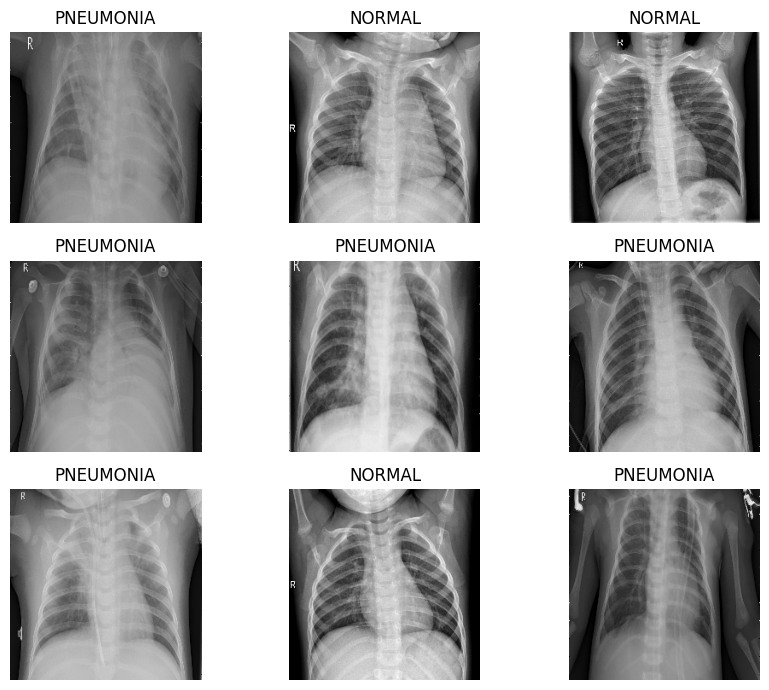

In [5]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(9, 7))
for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[int(labels[i].numpy()[0])])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
history = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 223s 1s/step - accuracy: 0.8740 - loss: 0.3173 - val_accuracy: 0.8125 - val_loss: 0.2438
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 213s 1s/step - accuracy: 0.9528 - loss: 0.1346 - val_accuracy: 0.8750 - val_loss: 0.2695
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 256s 1s/step - accuracy: 0.9580 - loss: 0.1136 - val_accuracy: 0.7500 - val_loss: 0.4105
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 267s 1s/step - accuracy: 0.9697 - loss: 0.0839 - val_accuracy: 1.0000 - val_loss: 0.1080
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 215s 1s/step - accuracy: 0.9732 - loss: 0.0761 - val_accuracy: 0.7500 - val_loss: 0.4785
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 217s 1s/step - accuracy: 0.9785 - loss: 0.0582 - val_accuracy: 0.9375 - val_loss: 0.1594
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 221s 1s/step - accuracy: 0.9839 - loss: 0.0458 - val_accuracy: 1.0000 - val_loss: 0.1394


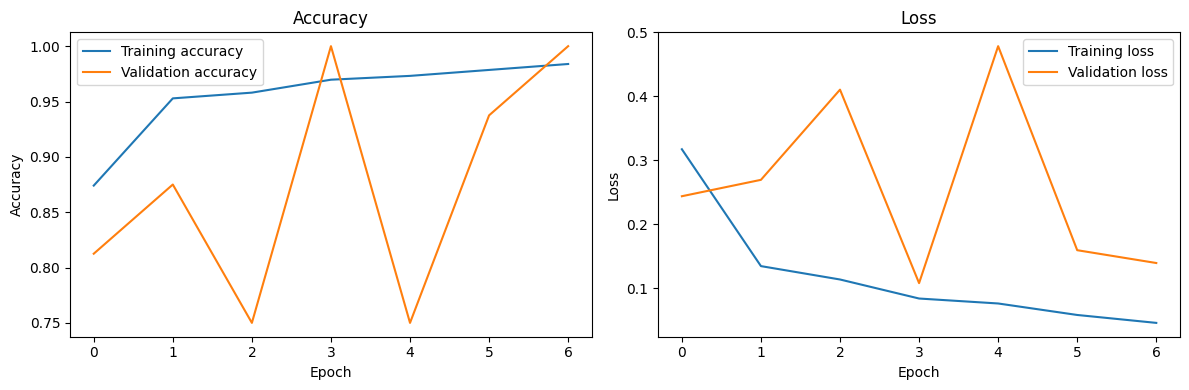

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.tight_layout(); plt.show()

Evaluation set: test
Loss: 1.0292
Accuracy: 0.7628
Precision: 0.7274
Recall: 0.9923
F1-score: 0.8395
              precision    recall  f1-score   support

      NORMAL       0.97      0.38      0.55       234
   PNEUMONIA       0.73      0.99      0.84       390

    accuracy                           0.76       624
   macro avg       0.85      0.69      0.69       624
weighted avg       0.82      0.76      0.73       624



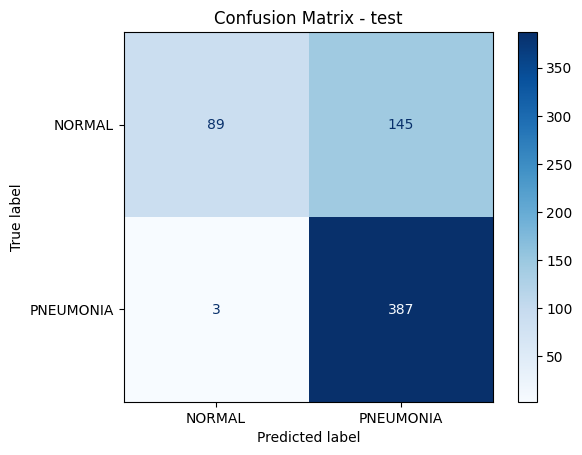

In [9]:
eval_ds = test_ds if test_ds is not None else val_ds
eval_name = "test" if test_ds is not None else "validation"
loss, _ = model.evaluate(eval_ds, verbose=0)
y_true = np.concatenate([y.numpy().ravel() for _, y in eval_ds]).astype(int)
y_prob = model.predict(eval_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Evaluation set:", eval_name)
print("Loss:", round(float(loss), 4))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - " + eval_name)
plt.show()

In [10]:
# Replace this path with an image file on your computer.
IMAGE_PATH = "path/to/your/chest_xray_image.jpeg"

if Path(IMAGE_PATH).is_file():
    img = tf.keras.utils.load_img(IMAGE_PATH, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img) / 255.0
    arr = np.expand_dims(arr, axis=0)
    score = float(model.predict(arr, verbose=0)[0][0])
    pred_idx = 1 if score >= 0.5 else 0
    print("Class order:", class_names)
    print("Predicted category:", class_names[pred_idx])
    print("Score for class index 1:", round(score, 4))
    plt.imshow(img); plt.axis("off"); plt.show()
else:
    print("Update IMAGE_PATH to the location of a chest X-ray image before running this cell.")

Update IMAGE_PATH to the location of a chest X-ray image before running this cell.


In [11]:
MODEL_PATH = "pneumonia_cnn_model.keras"
model.save(MODEL_PATH)
print("Saved model:", Path(MODEL_PATH).resolve())
print("Class order:", class_names)

Saved model: C:\Users\GAYATHRI\pneumonia_cnn_model.keras
Class order: ['NORMAL', 'PNEUMONIA']
